# Task 5 - GPT-2 Text Generation

This notebook explores GPT-2 generation strategies and attention heatmaps. GPT-2 is a decoder model, so it predicts the next token from the tokens before it.

## Notebook Settings

Environment and task variables used here:

- `MODEL_NAME = "gpt2"`
- `PROMPT = "The most surprising thing about artificial intelligence is"`
- `MAX_NEW_TOKENS = 45`
- `ATTENTION_MAX_TOKENS = 32`
- `SEED = 42`

The same prompt is used for every decoding strategy.

## Setup

In [1]:
from pathlib import Path
from IPython.display import Image, display
import random
import sys

import numpy as np
import pandas as pd
import torch

In [2]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.set_option("display.max_columns", None)

In [3]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [4]:
from src.config import EXAMPLES_DIR, METADATA_DIR, PLOTS_DIR, SEED
from src.generation_utils import (
    generate_text,
    generate_text_with_attentions,
    get_attention_matrix,
    load_gpt2_model,
)
from src.plotting import save_attention_heatmap
from src.result_saver import save_json, save_text

/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [6]:
for output_dir in [EXAMPLES_DIR, METADATA_DIR, PLOTS_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

## Load GPT-2

This uses the small GPT-2 model from HuggingFace.

In [7]:
MODEL_NAME = "gpt2"

In [8]:
MODEL_NAME

'gpt2'

In [9]:
tokenizer, model = load_gpt2_model(MODEL_NAME)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1955.58it/s]

In [10]:
print(type(tokenizer).__name__)
print(type(model).__name__)
print("layers:", model.config.n_layer)
print("heads:", model.config.n_head)

GPT2Tokenizer
GPT2LMHeadModel
layers: 12
heads: 12


## Prompt And Decoding Strategies

In [11]:
PROMPT = "The most surprising thing about artificial intelligence is"
MAX_NEW_TOKENS = 45

In [12]:
PROMPT, MAX_NEW_TOKENS

('The most surprising thing about artificial intelligence is', 45)

In [13]:
generation_strategies = [
    {
        "strategy": "greedy",
        "settings": {"do_sample": False},
    },
    {
        "strategy": "temperature_0_3",
        "settings": {"do_sample": True, "temperature": 0.3},
    },
    {
        "strategy": "temperature_1_0",
        "settings": {"do_sample": True, "temperature": 1.0},
    },
    {
        "strategy": "top_k",
        "settings": {"do_sample": True, "top_k": 50, "temperature": 0.8},
    },
    {
        "strategy": "top_p",
        "settings": {"do_sample": True, "top_p": 0.9, "temperature": 0.8},
    },
]

In [14]:
pd.DataFrame(generation_strategies)

,strategy,settings
0,greedy,{'do_sample': False}
1,temperature_0_3,"{'do_sample': True, 'temperature': 0.3}"
2,temperature_1_0,"{'do_sample': True, 'temperature': 1.0}"
3,top_k,"{'do_sample': True, 'top_k': 50, 'temperature': 0.8}"
4,top_p,"{'do_sample': True, 'top_p': 0.9, 'temperature': 0.8}"


## Generate Text

Each strategy uses the same prompt. Only the decoding settings change.

In [15]:
generated_rows = []

for strategy in generation_strategies:
    generated_text = generate_text(
        prompt=PROMPT,
        tokenizer=tokenizer,
        model=model,
        generation_kwargs=strategy["settings"],
        max_new_tokens=MAX_NEW_TOKENS,
        seed=SEED,
    )
    generated_rows.append({
        "strategy": strategy["strategy"],
        "settings": strategy["settings"],
        "generated_text": generated_text,
    })

In [16]:
generated_examples_df = pd.DataFrame(generated_rows)

In [17]:
generated_examples_df[["strategy", "generated_text"]]

,strategy,generated_text
0,greedy,The most surprising thing about artificial intelligence is that it's not just a tool for the rich. It's a tool for the poor.\n\nThe problem is that it's not just a tool for the rich. It's a tool for the poor.\n\n
1,temperature_0_3,The most surprising thing about artificial intelligence is that it's a very different animal than the ones we've seen before.\n\nIt's a very different animal than the ones we've seen before.\n\nIt's a very different animal than the ones we've seen
2,temperature_1_0,"The most surprising thing about artificial intelligence is that there isn't any artificial intelligence being taught in classrooms, to the detriment of students.""\n\nSo, if they want to be able to create an AI, you'd better understand how their skills relate to each other as"
3,top_k,"The most surprising thing about artificial intelligence is that there are a number of theories floating around about it, some of which may be completely wrong, some of which are completely valid. It's because there is so much evidence that we have these tools at our disposal that we"
4,top_p,"The most surprising thing about artificial intelligence is that there are a number of theories floating around about it, some of which may be completely wrong, some of which are completely valid. It's not just that there's no solid evidence for these theories. We know that computers"


**Observation: Strategy quality**

- `greedy`: coherent at first, but it repeats the same rich/poor sentence pattern, so it is too repetitive.
- `temperature_0_3`: controlled, but it also repeats the phrase about being "a very different animal," so the low temperature is not creative enough here.
- `temperature_1_0`: more surprising and creative, but it drifts into a less clear classroom example.
- `top_k`: more coherent than the high-temperature sample and less repetitive than greedy; it stays on the topic of theories and evidence.
- `top_p`: similar to top-k, with a natural continuation about theories and evidence. In this run, `top_k` and `top_p` produced the best text because they balanced variety with coherence.

In [18]:
generation_quality_notes = {
    "greedy": "Most deterministic. Check if it repeats a safe phrase or stays too predictable.",
    "temperature_0_3": "Low randomness. Usually more controlled, but can still sound conservative.",
    "temperature_1_0": "More randomness. Can be more creative, but may drift from the prompt.",
    "top_k": "Samples from likely tokens. Often balances variety and coherence.",
    "top_p": "Samples from a probability mass. Often flexible and natural when it works well.",
}

In [19]:
generation_quality_notes

{'greedy': 'Most deterministic. Check if it repeats a safe phrase or stays too predictable.',
 'temperature_0_3': 'Low randomness. Usually more controlled, but can still sound conservative.',
 'temperature_1_0': 'More randomness. Can be more creative, but may drift from the prompt.',
 'top_k': 'Samples from likely tokens. Often balances variety and coherence.',
 'top_p': 'Samples from a probability mass. Often flexible and natural when it works well.'}

In [20]:
generated_examples = generated_examples_df.to_dict("records")

In [21]:
save_json(
    data=generated_examples,
    output_path=EXAMPLES_DIR / "task5_generated_text_examples.json",
)

## Attention Text

This cell generates text while requesting attention outputs from GPT-2. The helper uses `model.generate(..., output_attentions=True, return_dict_in_generate=True)`. The heatmaps below use the generated text as the inspected sequence.

In [22]:
attention_text = generate_text_with_attentions(
    prompt=PROMPT,
    tokenizer=tokenizer,
    model=model,
    max_new_tokens=25,
)

In [23]:
attention_text

"The most surprising thing about artificial intelligence is that it's not just a tool for the rich. It's a tool for the poor.\n\nThe problem is that"

## Extract Attention Heads

The first heatmap uses an early layer. The second heatmap uses a later layer. This makes it easier to compare different attention patterns.

In [24]:
ATTENTION_MAX_TOKENS = 32

In [25]:
attention_matrix_1, attention_tokens_1 = get_attention_matrix(
    text=attention_text,
    tokenizer=tokenizer,
    model=model,
    layer_index=0,
    head_index=0,
    max_tokens=ATTENTION_MAX_TOKENS,
)

In [26]:
attention_matrix_1.shape, attention_tokens_1[:10]

((32, 32),
 ['The',
  'Ġmost',
  'Ġsurprising',
  'Ġthing',
  'Ġabout',
  'Ġartificial',
  'Ġintelligence',
  'Ġis',
  'Ġthat',
  'Ġit'])

In [27]:
attention_matrix_2, attention_tokens_2 = get_attention_matrix(
    text=attention_text,
    tokenizer=tokenizer,
    model=model,
    layer_index=6,
    head_index=3,
    max_tokens=ATTENTION_MAX_TOKENS,
)

In [28]:
attention_matrix_2.shape, attention_tokens_2[:10]

((32, 32),
 ['The',
  'Ġmost',
  'Ġsurprising',
  'Ġthing',
  'Ġabout',
  'Ġartificial',
  'Ġintelligence',
  'Ġis',
  'Ġthat',
  'Ġit'])

## Save Attention Heatmaps

In [29]:
save_attention_heatmap(
    attention_matrix=attention_matrix_1,
    tokens=attention_tokens_1,
    title="Task 5 GPT-2 Attention - Layer 0 Head 0",
    output_path=PLOTS_DIR / "task5_attention_head_1.png",
)

In [30]:
save_attention_heatmap(
    attention_matrix=attention_matrix_2,
    tokens=attention_tokens_2,
    title="Task 5 GPT-2 Attention - Layer 6 Head 3",
    output_path=PLOTS_DIR / "task5_attention_head_2.png",
)

In [31]:
print("saved:", PLOTS_DIR / "task5_attention_head_1.png")
print("saved:", PLOTS_DIR / "task5_attention_head_2.png")

saved: /home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/plots/task5_attention_head_1.png
saved: /home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/plots/task5_attention_head_2.png


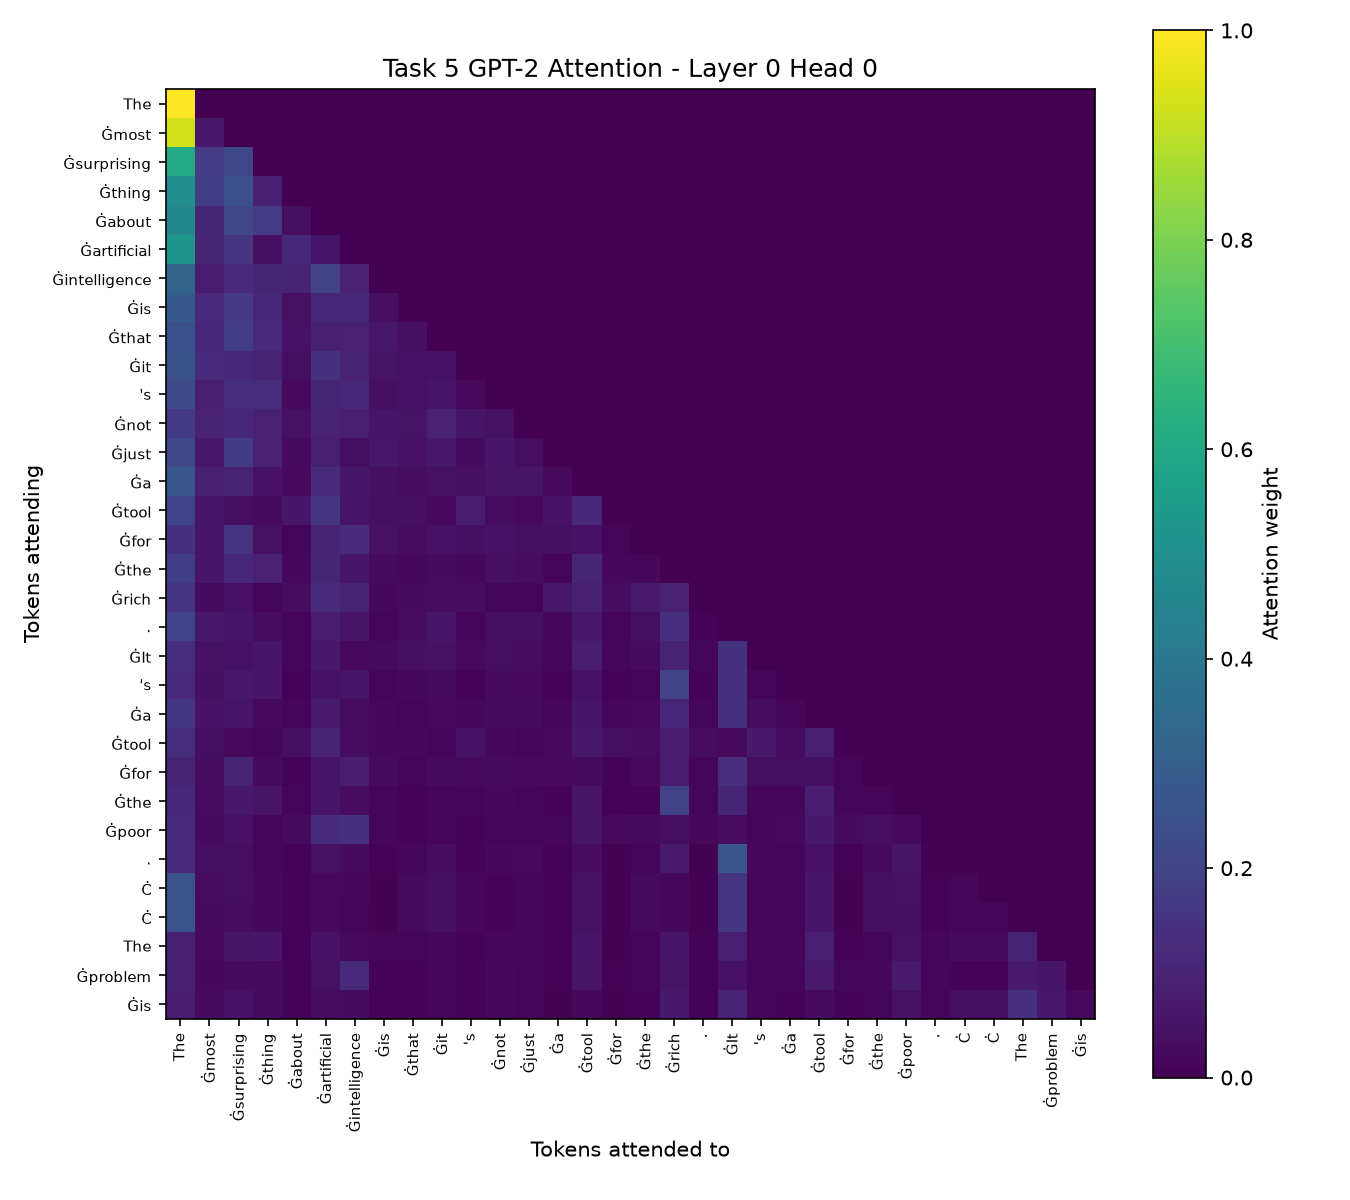

In [32]:
display(Image(filename=str(PLOTS_DIR / "task5_attention_head_1.png")))

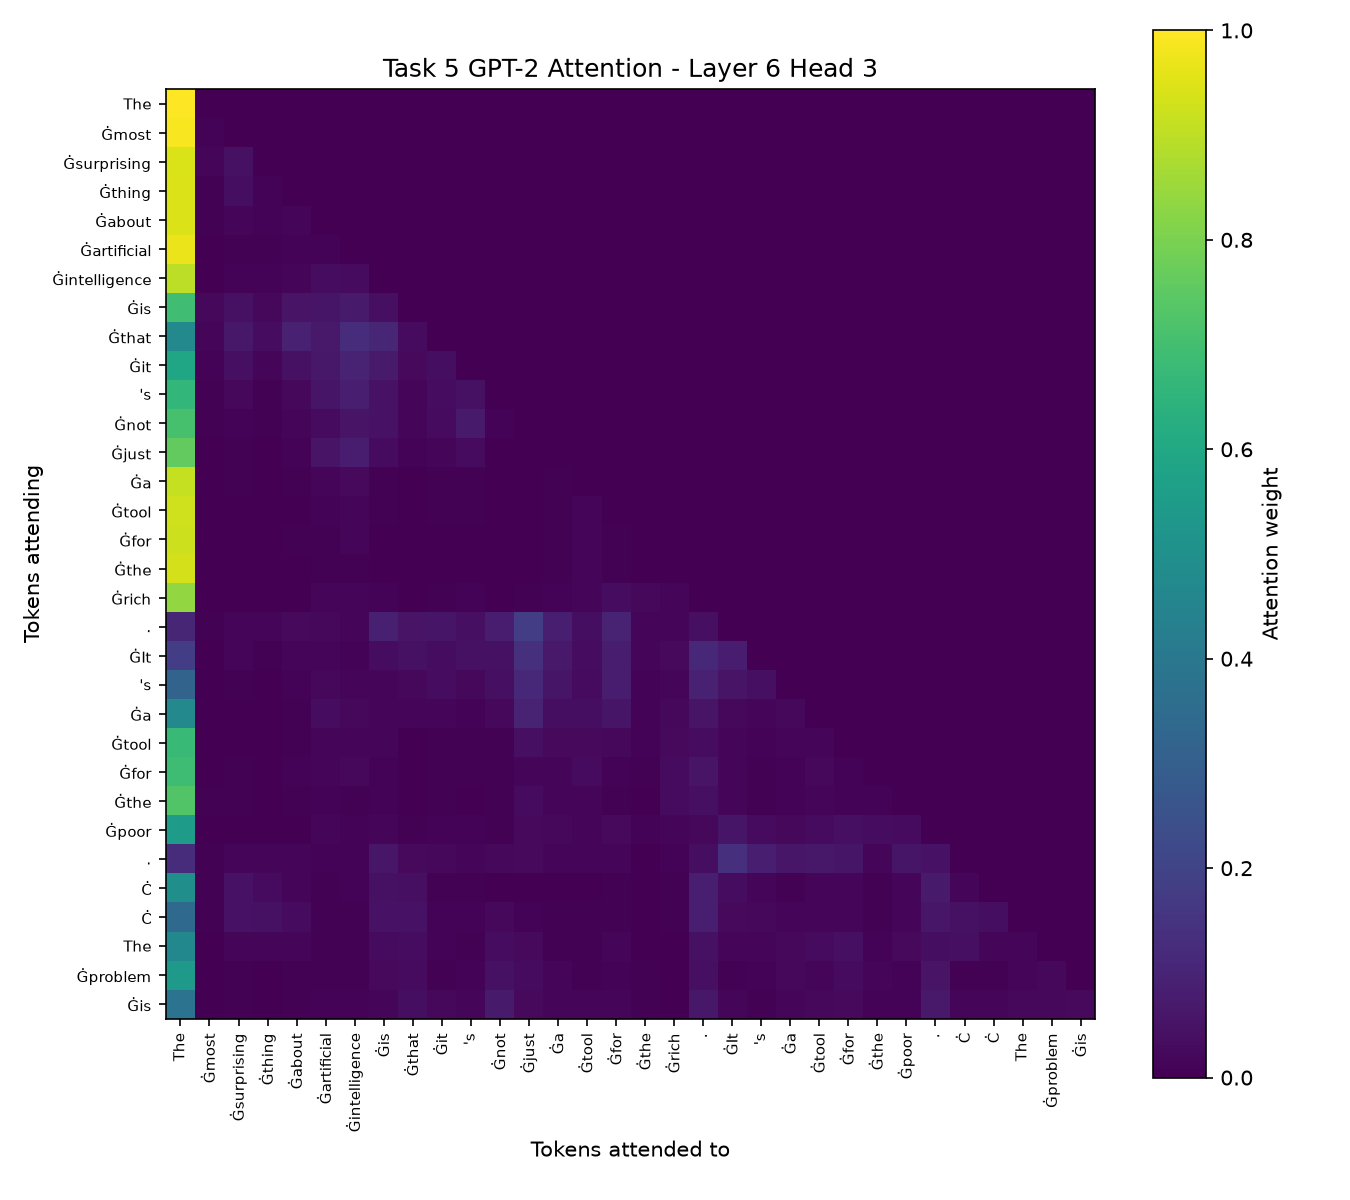

In [33]:
display(Image(filename=str(PLOTS_DIR / "task5_attention_head_2.png")))

**Interpretation question: What does the attention pattern reveal about what the model is "looking at" when it generates each token?**

The attention heatmaps show that GPT-2 looks backward at earlier tokens because it is a decoder-only model and cannot attend to future tokens. In Layer 0 Head 0, attention is concentrated mostly on the first token, which suggests that this head uses the start of the prompt as an anchor while later tokens are generated. In Layer 6 Head 3, attention is spread across more of the available previous tokens, suggesting that this later-layer head uses broader context from the prompt and generated continuation instead of focusing only on the first token.

## Attention Interpretation

The attention pattern shows which earlier tokens GPT-2 uses while producing later tokens. In this run, Layer 0 Head 0 focuses mostly on the first token, so it appears to use the beginning of the prompt as an anchor. Layer 6 Head 3 is more distributed across the previous tokens, which suggests that the later layer is combining broader context instead of relying only on the first token.

## Encoder vs Decoder

**When would you choose an encoder model like BERT over a decoder model like GPT-2?**

Choose an encoder model when the task is to understand an entire input at once. BERT reads text bidirectionally, so each token representation can use both left and right context. That makes it a natural fit for classification, sentiment analysis, named entity recognition, sentence similarity, reranking, and embedding/search workflows. In this project, Task 4 sentiment classification is a better match for DistilBERT than GPT-2 because the goal is to assign a label to a complete review, not continue the review.

**Can you use GPT-2 for classification?**

Yes, but it is not the most direct architecture for it. GPT-2 is a decoder-only model trained for next-token prediction, so classification usually requires an adaptation: add a classification head, prompt it to produce a label token, or score candidate label strings and choose the highest-probability one. This can work, but it is less natural than using an encoder because GPT-2 only conditions left-to-right and is optimized for continuation.

**Can you use BERT for generation?**

Not for normal open-ended left-to-right text generation in the same way as GPT-2. BERT is trained with masked language modeling, where it fills in missing tokens using both left and right context. That is useful for understanding and infilling, but it does not define a clean next-token generation process for producing long text one token at a time. Encoder-decoder models such as T5 or BART are better for conditional generation, while decoder-only models like GPT-2 are better for free-form continuation.

**Which architecture did the GPT-3, GPT-4, and Llama family inherit, and why did it win?**

They inherited the decoder-only, autoregressive architecture. It won for large language models because next-token prediction gives a simple and scalable training objective: train on massive text corpora by predicting the next token. The same objective directly supports open-ended generation, chat-style continuation, tool-use text formats, summarization, coding, and many other tasks through prompting. Decoder-only models also scale efficiently with model size and data, which made them the dominant architecture for general-purpose generative LLMs.

## Save Encoder vs Decoder Explanation

The frontend can read this saved markdown file instead of depending on notebook-only text.

In [34]:
encoder_decoder_explanation = '**When would you choose an encoder model like BERT over a decoder model like GPT-2?**\n\nChoose an encoder model when the task is to understand an entire input at once. BERT reads text bidirectionally, so each token representation can use both left and right context. That makes it a natural fit for classification, sentiment analysis, named entity recognition, sentence similarity, reranking, and embedding/search workflows. In this project, Task 4 sentiment classification is a better match for DistilBERT than GPT-2 because the goal is to assign a label to a complete review, not continue the review.\n\n**Can you use GPT-2 for classification?**\n\nYes, but it is not the most direct architecture for it. GPT-2 is a decoder-only model trained for next-token prediction, so classification usually requires an adaptation: add a classification head, prompt it to produce a label token, or score candidate label strings and choose the highest-probability one. This can work, but it is less natural than using an encoder because GPT-2 only conditions left-to-right and is optimized for continuation.\n\n**Can you use BERT for generation?**\n\nNot for normal open-ended left-to-right text generation in the same way as GPT-2. BERT is trained with masked language modeling, where it fills in missing tokens using both left and right context. That is useful for understanding and infilling, but it does not define a clean next-token generation process for producing long text one token at a time. Encoder-decoder models such as T5 or BART are better for conditional generation, while decoder-only models like GPT-2 are better for free-form continuation.\n\n**Which architecture did the GPT-3, GPT-4, and Llama family inherit, and why did it win?**\n\nThey inherited the decoder-only, autoregressive architecture. It won for large language models because next-token prediction gives a simple and scalable training objective: train on massive text corpora by predicting the next token. The same objective directly supports open-ended generation, chat-style continuation, tool-use text formats, summarization, coding, and many other tasks through prompting. Decoder-only models also scale efficiently with model size and data, which made them the dominant architecture for general-purpose generative LLMs.'

save_text(
    text=encoder_decoder_explanation,
    output_path=EXAMPLES_DIR / "task5_encoder_decoder_explanation.md",
)

## Save Summary

In [35]:
task5_summary = {
    "task": "Task 5 - GPT-2 Text Generation",
    "model_name": MODEL_NAME,
    "prompt": PROMPT,
    "max_new_tokens": MAX_NEW_TOKENS,
    "strategies": [row["strategy"] for row in generated_rows],
    "attention_layers_heads": [
        {"layer": 0, "head": 0, "plot": "task5_attention_head_1.png"},
        {"layer": 6, "head": 3, "plot": "task5_attention_head_2.png"},
    ],
    "best_strategy_observed": "top_k or top_p",
    "main_result": "Greedy and low-temperature decoding were repetitive, while top-k and top-p gave the best balance of coherence and variety in this run.",
    "attention_interpretation": "The heatmaps show GPT-2 looking backward at earlier tokens. Layer 0 Head 0 is concentrated mostly on the first token, while Layer 6 Head 3 spreads attention across more previous tokens and uses broader context.",
    "encoder_decoder_explanation_file": "task5_encoder_decoder_explanation.md",
    "encoder_decoder_explanation": encoder_decoder_explanation,
    "interpretation": "Attention heatmaps show which earlier tokens GPT-2 looks at while predicting later tokens.",
}

In [36]:
save_json(
    data=task5_summary,
    output_path=METADATA_DIR / "task5_generation_summary.json",
)

## Final Answer

The best decoding strategy in this run is either `top_k` or `top_p`, because both gave more varied text than greedy decoding without drifting as much as temperature `1.0`. Greedy and low-temperature decoding were coherent but repetitive. The attention plots show that GPT-2 generates by looking backward at earlier tokens: Layer 0 Head 0 mostly anchors on the first token, while Layer 6 Head 3 uses a broader spread of previous tokens. Encoder models like BERT are better for understanding a complete input, while decoder models like GPT-2 are better for continuing text. Decoder-only models became the base for GPT-style and Llama-style systems because next-token generation scales well for open-ended language tasks.